# DataSEC 2026 – Final: Robustness of Environmental Sound Classifiers (RQ1)

**Research question.** How robust are environmental sound classifiers when the target sound is perturbed by realistic acoustic noise, temporal distortions and spectral corruptions?

**Protocol.** The clean test set and the three trained models from the Midterm are reused unchanged. Test labels are never changed. Corruptions are applied **at test time only**; no model is retrained and no perturbation parameter is tuned on test results.

**Perturbations (6, each at 3 severities; pink noise and other-class background mixing both at SNR +20 / +10 / 0 dB):** additive pink noise (SNR +20 / +10 / 0 dB), gain (+6 / −6 / −12 dB), circular time shift (0.5 / 1 / 2 s), time masking (10 / 25 / 50 % of the 4 s window), frequency masking (10 / 25 / 50 % of the 0–11.025 kHz range).

**Needs from the Midterm run** (same Drive folder): `ckpt_*.pt`, `config.json`, `split_indices.csv`, `baseline_results.csv`.

**Run:** Colab → T4 GPU → Run all. Everything is saved to `OUT_DIR`.

In [1]:
!pip -q install soundfile librosa seaborn scikit-learn scipy

In [2]:
import os, sys, json, time, random, copy, zipfile, platform, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import torchaudio, torchvision, soundfile as sf, librosa, sklearn, scipy
import matplotlib.pyplot as plt
import seaborn as sns
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from scipy.stats import spearmanr

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if USE_AMP else "CPU")

# Perturbation grid. The order of `levels` defines severity 1, 2, 3.
BOOTSTRAP = 200          # paired bootstrap resamples for the dF1 confidence interval
POOL_PER_CLASS = 15      # background pool for "noise_mix": train clips (>= 4 s) per class
PERTURBATIONS = {
    "noise_pink": dict(label="Additive pink noise", unit="dB SNR", levels=[20, 10, 0]),
    "noise_mix":  dict(label="Background mixing",   unit="dB SNR", levels=[20, 10, 0]),
    "gain":       dict(label="Gain",                unit="dB",     levels=[6, -6, -12]),
    "shift":      dict(label="Circular time shift", unit="s",      levels=[0.5, 1.0, 2.0]),
    "time_mask":  dict(label="Time masking",        unit="fraction of window", levels=[0.10, 0.25, 0.50]),
    "freq_mask":  dict(label="Frequency masking",   unit="fraction of 0-11 kHz", levels=[0.10, 0.25, 0.50]),
}
PERT_ID = {k: i + 1 for i, k in enumerate(PERTURBATIONS)}

Device: cuda | Tesla T4


In [3]:
# ---------------- Paths ----------------
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass

ZIP_PATH    = Path(os.environ.get("DATASEC_ZIP", "/content/drive/MyDrive/ATI G6/DATASEC.zip"))
MID_DIR     = Path(os.environ.get("MID_DIR", "/content/drive/MyDrive/ATI G6/datasec_midterm"))
OUT_DIR     = Path(os.environ.get("OUT_DIR", "/content/drive/MyDrive/ATI G6/datasec_final"))
EXTRACT_DIR = Path(os.environ.get("EXTRACT_DIR", "/content/DATASEC_extracted"))
OUT_DIR.mkdir(parents=True, exist_ok=True)

if not any(EXTRACT_DIR.rglob("*.wav")):
    print("Extracting the dataset (~6 GB, a few minutes)...")
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(EXTRACT_DIR)
ROOT = EXTRACT_DIR / "DATASEC" if (EXTRACT_DIR / "DATASEC").is_dir() else EXTRACT_DIR

MCFG = json.load(open(MID_DIR / "config.json"))           # Midterm feature configuration
SR, DUR = MCFG["sample_rate"], MCFG["duration"]
NFFT, HOP, NMELS = MCFG["n_fft"], MCFG["hop_length"], MCFG["n_mels"]
CLASSES = MCFG["classes"]; K = len(CLASSES)
TARGET = int(round(DUR * SR))

# Fixed split from the Midterm (never recomputed here)
split = pd.read_csv(MID_DIR / "split_indices.csv")
shutil.copy(MID_DIR / "split_indices.csv", OUT_DIR / "split_indices.csv")

rows = []
for p in sorted(ROOT.rglob("*.wav")):
    rel = p.relative_to(ROOT).parts
    if any(s.startswith(("__", ".")) for s in rel):
        continue
    info = sf.info(str(p))
    rows.append(dict(sample_id=Path(*rel).as_posix(), path=str(p), sr=info.samplerate, frames=info.frames,
                     duration=info.frames / info.samplerate))
meta = pd.DataFrame(rows).merge(split, on="sample_id", how="inner")
assert len(meta) == len(split), "Dataset files do not match split_indices.csv (wrong dataset version?)"
assert sorted(meta.macro_class.unique()) == CLASSES
assert (meta.macro_class.map({c: i for i, c in enumerate(CLASSES)}) == meta.label).all()
test_df = meta[meta.split == "test"].reset_index(drop=True)
N = len(test_df); Y = test_df.label.values
print(f"Test clips: {N} | classes: {K} | dataset root: {ROOT}")

Mounted at /content/drive
Extracting the dataset (~6 GB, a few minutes)...
Test clips: 758 | classes: 22 | dataset root: /content/DATASEC_extracted/DATASEC


In [4]:
# ---------------- Same pipeline and models as the Midterm (evaluation only) ----------------
class AudioDS(Dataset):
    def __init__(self, df):
        df = df.reset_index(drop=True)
        self.paths = df.path.tolist(); self.sr = df.sr.astype(int).tolist()
        self.frames = df.frames.astype(int).tolist(); self.labels = df.label.astype(int).tolist(); self._rs = {}
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        sr, n = self.sr[i], self.frames[i]
        need = int(round(DUR * sr))
        start = (n - need) // 2 if n > need else 0          # center crop (same as Midterm val/test)
        y, _ = sf.read(self.paths[i], start=start, frames=min(need, n), dtype="float32", always_2d=True)
        y = torch.from_numpy(y.mean(axis=1))
        if sr != SR:
            if sr not in self._rs: self._rs[sr] = torchaudio.transforms.Resample(sr, SR)
            y = self._rs[sr](y)
        y = y[:TARGET]
        if y.numel() < TARGET: y = F.pad(y, (0, TARGET - y.numel()))
        return y.unsqueeze(0), self.labels[i], i

class LogMel(nn.Module):
    def __init__(self):
        super().__init__()
        self.mel = torchaudio.transforms.MelSpectrogram(sample_rate=SR, n_fft=NFFT, hop_length=HOP, n_mels=NMELS, power=2.0)
        self.db = torchaudio.transforms.AmplitudeToDB(stype="power", top_db=MCFG["top_db"])
        self.register_buffer("mean", torch.tensor(float(MCFG["norm_mean"])))
        self.register_buffer("std", torch.tensor(float(MCFG["norm_std"])))
    def raw_db(self, wav):
        with torch.autocast(device_type=wav.device.type, enabled=False):
            return self.db(self.mel(wav.float()))
    def forward(self, wav):
        return (self.raw_db(wav) - self.mean) / self.std
frontend = LogMel().to(DEVICE)

def conv_block(cin, cout):
    return nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))

class SmallCNN(nn.Module):
    def __init__(self, k=22):
        super().__init__()
        self.features = nn.Sequential(conv_block(1, 32), nn.MaxPool2d(2), conv_block(32, 64), nn.MaxPool2d(2),
                                      conv_block(64, 128), nn.AdaptiveAvgPool2d(1))
        self.drop = nn.Dropout(0.3); self.fc = nn.Linear(128, k)
    def forward(self, x): return self.fc(self.drop(torch.flatten(self.features(x), 1)))

class MobileNetV3S(nn.Module):
    def __init__(self, k=22):
        super().__init__()
        m = torchvision.models.mobilenet_v3_small(weights=None)      # weights come from the Midterm checkpoint
        m.classifier[3] = nn.Linear(m.classifier[3].in_features, k); self.m = m
    def forward(self, x): return self.m(x.expand(-1, 3, -1, -1))

class CRNN(nn.Module):
    def __init__(self, k=22, n_mels=NMELS, hidden=128):
        super().__init__()
        self.cnn = nn.Sequential(conv_block(1, 32), nn.MaxPool2d(2), conv_block(32, 64), nn.MaxPool2d(2))
        self.gru = nn.GRU(64 * (n_mels // 4), hidden, batch_first=True, bidirectional=True)
        self.drop = nn.Dropout(0.3); self.fc = nn.Linear(4 * hidden, k)
    def forward(self, x):
        x = self.cnn(x).permute(0, 3, 1, 2).flatten(2)
        out, _ = self.gru(x)
        return self.fc(self.drop(torch.cat([out.mean(1), out.amax(1)], dim=1)))

MODELS = {"Small CNN": SmallCNN, "MobileNetV3-Small": MobileNetV3S, "CRNN": CRNN}
NETS = {}
for name, M in MODELS.items():
    ck = torch.load(MID_DIR / f"ckpt_{name.replace(' ', '_')}.pt", map_location="cpu", weights_only=False)
    net = M(K); net.load_state_dict(ck["state"]); NETS[name] = net.to(DEVICE).eval()
print("Loaded:", list(NETS))

Loaded: ['Small CNN', 'MobileNetV3-Small', 'CRNN']


In [5]:
# Load the clean test waveforms once (758 x 4 s, ~270 MB) so every condition reuses them
loader = DataLoader(AudioDS(test_df), batch_size=64, shuffle=False, num_workers=2)
TEST_WAV = torch.cat([w for w, _, _ in loader]).to(DEVICE)               # [N,1,T]
VALID = np.minimum(TARGET, np.round(test_df.duration.values * SR).astype(int))   # samples that are real audio (not padding)
print("TEST_WAV", tuple(TEST_WAV.shape), "| clips shorter than 4 s:", int((VALID < TARGET).sum()))

# Background pool for "noise_mix": train-split clips (>= 4 s, so no padding) of every class, centre-cropped like all other audio
pool_meta = meta[(meta.split == "train") & (meta.duration >= DUR)].sample(frac=1.0, random_state=SEED)
pool_meta = pool_meta.groupby("macro_class", group_keys=False).head(POOL_PER_CLASS).reset_index(drop=True)
_pl = DataLoader(AudioDS(pool_meta), batch_size=64, shuffle=False, num_workers=2)
POOL_WAV = torch.cat([w for w, _, _ in _pl]).to(DEVICE)[:, 0]           # [P,T]
POOL_LAB = pool_meta.label.values
POOL_CAND = {c: np.where(POOL_LAB != c)[0] for c in range(K)}            # the background must come from a different class
print("Background pool:", tuple(POOL_WAV.shape), "clips from", pool_meta.macro_class.nunique(), "classes")


TEST_WAV (758, 1, 88200) | clips shorter than 4 s: 255
Background pool: (324, 88200) clips from 22 classes


## Perturbations
All perturbations act on the **waveform**, before the log-Mel front end, and are deterministic: the random draws for sample *i*, perturbation *p*, severity *s* come from a generator seeded by `(seed, p, s, i)`, so any example can be regenerated exactly.

- **Additive pink noise** (1/f spectrum, synthetic stand-in for broadband urban background): scaled so that `10·log10(P_signal / P_noise)` equals the target SNR, where `P_signal` is measured over the real audio only (zero padding excluded). The noise is added over the whole 4 s window.
- **Background mixing** (`noise_mix`): a train-split clip of a *different* class (>= 4 s, centre-cropped) is added as background. Its power is scaled over the 4 s window so that the SNR relative to the real audio equals the target. It is an interfering real sound, not stationary ambient noise (DataSEC has no pure ambient recordings).
- **Gain**: waveform multiplied by `10^(dB/20)`.
- **Circular shift**: `torch.roll` of the 4 s window.
- **Time masking**: 4 random intervals set to zero, together covering the stated fraction of the window.
- **Frequency masking**: STFT (n_fft 2048, hop 512), 2 random frequency bands set to zero covering the stated fraction of bins, then inverse STFT.

In [6]:
WIN = torch.hann_window(NFFT, device=DEVICE)

def _gen(pert, sev, idx):
    g = torch.Generator(device=DEVICE)
    g.manual_seed((SEED * 1_000_003 + PERT_ID[pert] * 10_007 + sev * 101 + int(idx) * 7919) % (2**31 - 1))
    return g

def perturb(x, pert, sev, idx, valid):
    # x: [1,T] on DEVICE -> perturbed [1,T]
    level = PERTURBATIONS[pert]["levels"][sev - 1]; T = x.shape[-1]
    if pert == "gain":
        return x * (10 ** (level / 20))
    if pert == "shift":
        return torch.roll(x, int(round(level * SR)), dims=-1)
    g = _gen(pert, sev, idx)
    if pert == "noise_pink":
        white = torch.randn(T, generator=g, device=x.device)
        f = torch.fft.rfftfreq(T, d=1.0 / SR, device=x.device)
        pink = torch.fft.irfft(torch.fft.rfft(white) / torch.sqrt(f.clamp(min=f[1])), n=T)
        v = int(valid)
        pink = pink / pink[:v].pow(2).mean().sqrt().clamp(min=1e-10)      # unit power over the real-audio region
        p_sig = x[..., :v].pow(2).mean().clamp(min=1e-10)
        return x + pink.unsqueeze(0) * torch.sqrt(p_sig / (10 ** (level / 10)))
    if pert == "noise_mix":
        cand = POOL_CAND[int(Y[idx])]
        nz = POOL_WAV[cand[int(torch.randint(len(cand), (1,), generator=g, device=x.device))]]
        p_sig = x[..., :int(valid)].pow(2).mean().clamp(min=1e-10)
        return x + nz.unsqueeze(0) * torch.sqrt(p_sig / (nz.pow(2).mean().clamp(min=1e-10) * 10 ** (level / 10)))
    if pert == "time_mask":
        n = 4; slot = T // n; L = max(1, int(level * slot)); out = x.clone()      # one interval per slot, no overlap
        for k, o in enumerate(torch.randint(0, slot - L + 1, (n,), generator=g, device=x.device).tolist()):
            out[..., k * slot + o:k * slot + o + L] = 0
        return out
    if pert == "freq_mask":
        X = torch.stft(x[0], NFFT, HOP, window=WIN, return_complex=True).clone()
        n = 2; slot = X.shape[0] // n; W = max(1, int(level * slot))              # one band per half of the spectrum
        for k, o in enumerate(torch.randint(0, slot - W + 1, (n,), generator=g, device=x.device).tolist()):
            X[k * slot + o:k * slot + o + W, :] = 0
        return torch.istft(X, NFFT, HOP, window=WIN, length=T).unsqueeze(0)
    raise ValueError(pert)

def perturb_all(pert, sev):
    return torch.stack([perturb(TEST_WAV[i], pert, sev, i, VALID[i]) for i in range(N)])

# ---- sanity checks on 5 clips ----
for i in range(5):
    x, v = TEST_WAV[i], VALID[i]
    for sev in range(1, 4):
        lvl = PERTURBATIONS["noise_pink"]["levels"][sev - 1]
        y = perturb(x, "noise_pink", sev, i, v)
        meas = 10 * torch.log10(x[..., :v].pow(2).mean() / (y - x)[..., :v].pow(2).mean()).item()
        assert abs(meas - lvl) < 0.5, ("pink", i, lvl, meas)
        y = perturb(x, "noise_mix", sev, i, v)
        meas = 10 * torch.log10(x[..., :v].pow(2).mean() / (y - x).pow(2).mean()).item()
        assert abs(meas - lvl) < 0.5, ("mix", i, lvl, meas)
    assert torch.allclose(perturb(x, "gain", 3, i, v), x * 10 ** (-12 / 20))
    assert (perturb(x, "time_mask", 3, i, v) == 0).float().mean() >= 0.49
    assert torch.equal(perturb(x, "noise_mix", 2, i, v), perturb(x, "noise_mix", 2, i, v)), "perturbations must be deterministic"
print("Perturbation sanity checks passed (measured SNR within 0.5 dB of target, deterministic draws).")


Perturbation sanity checks passed (measured SNR within 0.5 dB of target, deterministic draws).


## Evaluation of every model under every condition
19 conditions (clean + 6 perturbations × 3 severities) × 3 models on the 758 test clips. The clean condition must reproduce the Midterm test numbers.

In [7]:
@torch.no_grad()
def predict(net, wavs, bs=128):
    out = []
    for i in range(0, len(wavs), bs):
        x = frontend(wavs[i:i + bs])
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            logits = net(x)
        out.append(torch.softmax(logits.float(), 1).cpu())
    return torch.cat(out).numpy()

CONDS = [("clean", 0)] + [(p, s) for p in PERTURBATIONS for s in (1, 2, 3)]
P = {m: {} for m in NETS}                                   # P[model][(pert, sev)] -> probabilities [N,K]
t0 = time.time()
for pert, sev in CONDS:
    wavs = TEST_WAV if pert == "clean" else perturb_all(pert, sev)
    for m, net in NETS.items():
        P[m][(pert, sev)] = predict(net, wavs)
    del wavs
    print(f"{pert:11s} sev {sev} done ({time.time() - t0:.0f}s)")

def mf1(y, pr): return f1_score(y, pr, average="macro", labels=list(range(K)), zero_division=0)
def fast_f1(y, p):
    # per-class F1 from confusion counts (same as sklearn average=None, zero_division=0); used for the bootstrap
    cm = np.bincount(y * K + p, minlength=K * K).reshape(K, K).astype(float)
    tp = np.diag(cm); den = 2 * tp + (cm.sum(0) - tp) + (cm.sum(1) - tp)
    return np.divide(2 * tp, den, out=np.zeros(K), where=den > 0)

base = pd.read_csv(MID_DIR / "baseline_results.csv").set_index("model")
for m in NETS:
    pr = P[m][("clean", 0)].argmax(1); f = mf1(Y, pr); ref = base.loc[m, "test_macroF1"]
    print(f"{m:18s} clean macro-F1 {f:.4f} (Midterm: {ref:.4f})")
    assert abs(f - ref) < 0.01, f"{m}: clean Macro-F1 differs from the Midterm -> wrong split, checkpoint or pipeline"
print("Clean results reproduce the Midterm test numbers.")


clean       sev 0 done (4s)
noise_pink  sev 1 done (5s)
noise_pink  sev 2 done (6s)
noise_pink  sev 3 done (6s)
noise_mix   sev 1 done (7s)
noise_mix   sev 2 done (8s)
noise_mix   sev 3 done (8s)
gain        sev 1 done (9s)
gain        sev 2 done (9s)
gain        sev 3 done (9s)
shift       sev 1 done (10s)
shift       sev 2 done (10s)
shift       sev 3 done (11s)
time_mask   sev 1 done (11s)
time_mask   sev 2 done (12s)
time_mask   sev 3 done (12s)
freq_mask   sev 1 done (14s)
freq_mask   sev 2 done (15s)
freq_mask   sev 3 done (15s)
Small CNN          clean macro-F1 0.7140 (Midterm: 0.7140)
MobileNetV3-Small  clean macro-F1 0.8975 (Midterm: 0.8975)
CRNN               clean macro-F1 0.8363 (Midterm: 0.8363)
Clean results reproduce the Midterm test numbers.


In [8]:
# Required comparison: F1_clean, F1_corrupted, delta F1 per model / perturbation / severity (+ paired bootstrap 95% CI of delta F1)
def level_str(p, s):
    return "clean" if p == "clean" else f"{PERTURBATIONS[p]['levels'][s - 1]} {PERTURBATIONS[p]['unit']}"

BIDX = np.random.RandomState(0).randint(0, N, (BOOTSTRAP, N))        # same resamples for every model and condition
rows = []
for m in NETS:
    pc = P[m][("clean", 0)].argmax(1); f_clean = mf1(Y, pc)
    boot_clean = np.array([fast_f1(Y[b], pc[b]).mean() for b in BIDX])
    for p, s in CONDS:
        pr = P[m][(p, s)].argmax(1); f = mf1(Y, pr)
        if p == "clean": lo = hi = 0.0
        else:
            d = boot_clean - np.array([fast_f1(Y[b], pr[b]).mean() for b in BIDX]); lo, hi = np.percentile(d, [2.5, 97.5])
        rows.append(dict(model=m, perturbation=p, severity=s, level=level_str(p, s), accuracy=accuracy_score(Y, pr),
                         macro_f1_clean=f_clean, macro_f1_corrupted=f, delta_f1=f_clean - f, delta_f1_ci_low=lo, delta_f1_ci_high=hi))
rob = pd.DataFrame(rows).round(4)
rob.to_csv(OUT_DIR / "robustness_results.csv", index=False)

pd.set_option("display.width", 220, "display.max_rows", 200)
print(rob.pivot_table(index=["perturbation", "severity", "level"], columns="model", values="macro_f1_corrupted", sort=False).to_string())
summ = rob[rob.perturbation != "clean"].groupby(["perturbation", "model"]).delta_f1.agg(mean_delta="mean", worst_delta="max").round(3)
summ.to_csv(OUT_DIR / "delta_f1_summary.csv"); print("\nDelta F1 (clean - corrupted), mean and worst over 3 severities:"); print(summ.to_string())
print("\nA drop is distinguishable from sampling noise when its 95% CI (delta_f1_ci_low .. delta_f1_ci_high) excludes 0.")


model                                            Small CNN  MobileNetV3-Small    CRNN
perturbation severity level                                                          
clean        0        clean                         0.7140             0.8975  0.8363
noise_pink   1        20 dB SNR                     0.3593             0.7704  0.6510
             2        10 dB SNR                     0.2340             0.5924  0.4638
             3        0 dB SNR                      0.0595             0.3237  0.2044
noise_mix    1        20 dB SNR                     0.4711             0.6911  0.6603
             2        10 dB SNR                     0.3316             0.4690  0.4470
             3        0 dB SNR                      0.1873             0.2119  0.2459
gain         1        6 dB                          0.6917             0.8982  0.8335
             2        -6 dB                         0.7137             0.8975  0.8392
             3        -12 dB                        0.

In [9]:
# Saved prediction probabilities: sample_id,true_class,pred_class,probabilities,duration,model,split,perturbation,severity
parts = []
for m in NETS:
    for p, s in CONDS:
        pr = P[m][(p, s)]
        parts.append(pd.DataFrame(dict(
            sample_id=test_df.sample_id, true_class=[CLASSES[i] for i in Y], pred_class=[CLASSES[i] for i in pr.argmax(1)],
            probabilities=[json.dumps([round(float(v), 5) for v in row]) for row in pr],
            duration=test_df.duration.round(3), model=m, split="test", perturbation=p, severity=s)))
pd.concat(parts, ignore_index=True).to_csv(OUT_DIR / "predictions_final.csv", index=False)
print("predictions_final.csv:", sum(len(x) for x in parts), "rows")

predictions_final.csv: 43206 rows


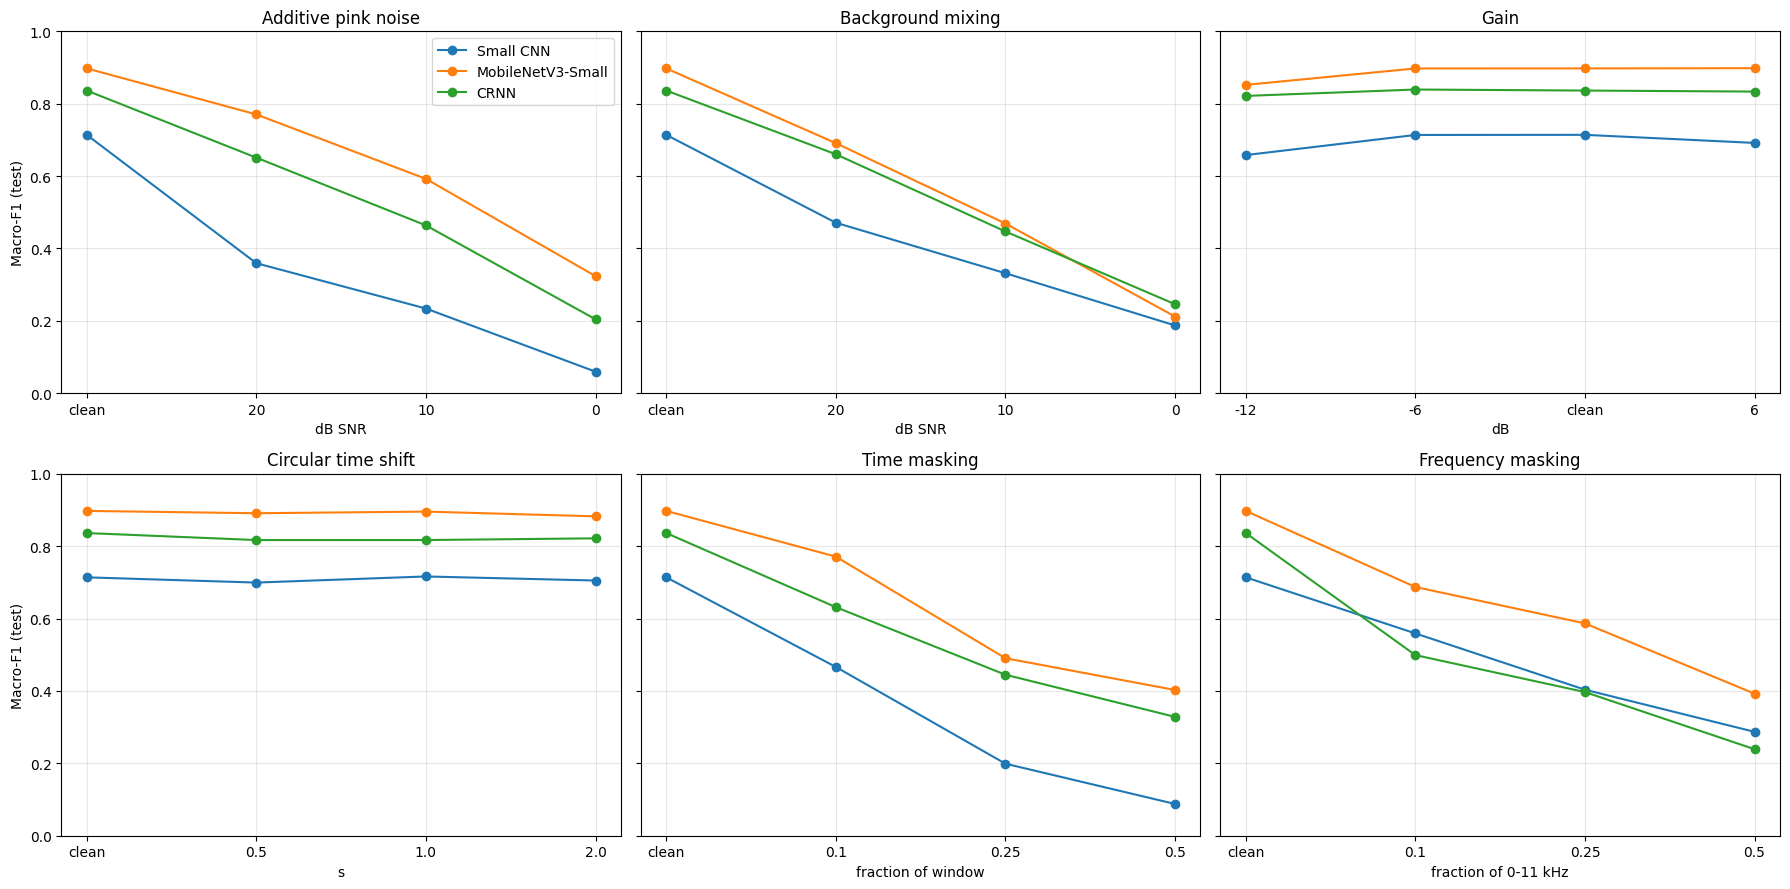

In [10]:
# Degradation curves across severity, one panel per perturbation (gain is ordered by dB so the curve reads left to right)
ORDER = {"gain": [3, 2, 0, 1]}                                    # -12 dB, -6 dB, clean, +6 dB
fig, axes = plt.subplots(2, 3, figsize=(18, 9), sharey=True)
for ax, (p, cfg) in zip(axes.flat, PERTURBATIONS.items()):
    order = ORDER.get(p, [0, 1, 2, 3])
    xs = ["clean" if s == 0 else str(cfg["levels"][s - 1]) for s in order]
    for m in NETS:
        ys = [mf1(Y, P[m][("clean", 0) if s == 0 else (p, s)].argmax(1)) for s in order]
        ax.plot(xs, ys, marker="o", label=m)
    ax.set_title(cfg["label"]); ax.set_xlabel(cfg["unit"]); ax.grid(alpha=0.3); ax.set_ylim(0, 1)
for ax in axes[:, 0]: ax.set_ylabel("Macro-F1 (test)")
axes[0, 0].legend(); plt.tight_layout(); plt.savefig(OUT_DIR / "degradation_curves.png", dpi=150); plt.show()


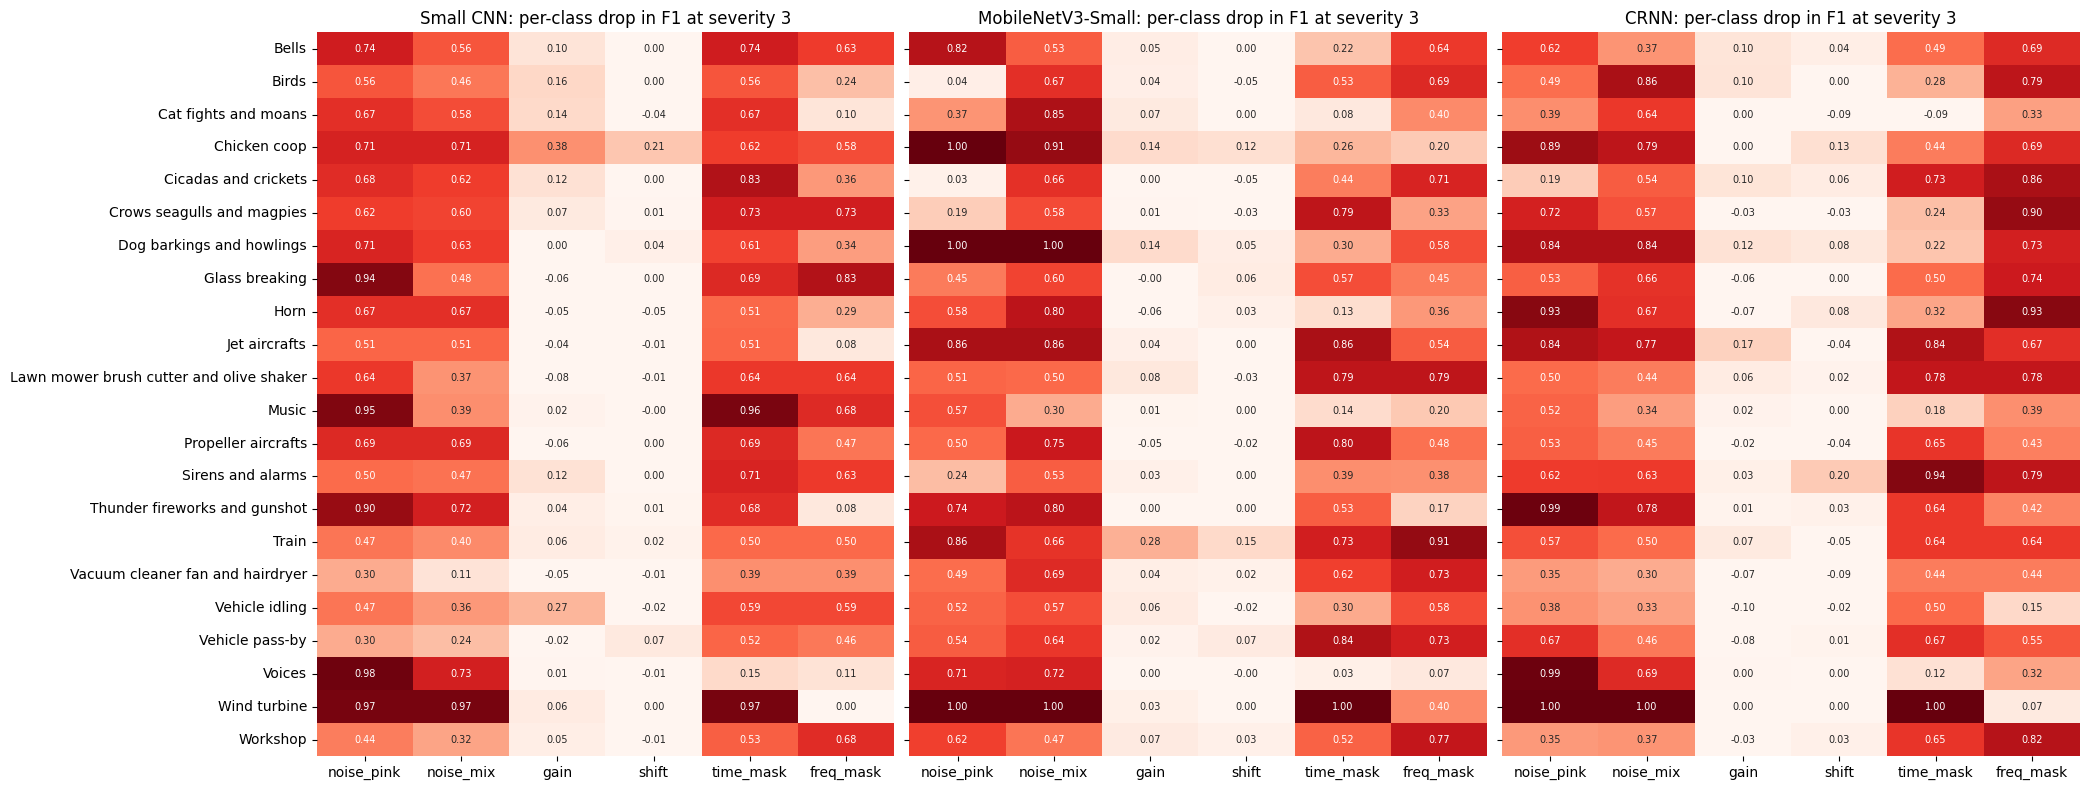

Most affected classes at severity 3 (mean drop over models and perturbations):
cls
Wind turbine                     0.526
Chicken coop                     0.489
Dog barkings and howlings        0.456
Jet aircrafts                    0.443
Train                            0.438
Thunder fireworks and gunshot    0.420


In [11]:
# Per-class degradation: F1_clean - F1_corrupted for each class
recs = []
for m in NETS:
    f_c = f1_score(Y, P[m][("clean", 0)].argmax(1), average=None, labels=list(range(K)), zero_division=0)
    for p in PERTURBATIONS:
        for s in (1, 2, 3):
            f_p = f1_score(Y, P[m][(p, s)].argmax(1), average=None, labels=list(range(K)), zero_division=0)
            for k in range(K):
                recs.append(dict(model=m, perturbation=p, severity=s, cls=CLASSES[k], n_test=int((Y == k).sum()),
                                 f1_clean=f_c[k], f1_corrupted=f_p[k], delta=f_c[k] - f_p[k]))
pcd = pd.DataFrame(recs).round(3); pcd.to_csv(OUT_DIR / "per_class_degradation.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(21, 8), sharey=True)
for ax, m in zip(axes, NETS):
    piv = pcd[(pcd.model == m) & (pcd.severity == 3)].pivot(index="cls", columns="perturbation", values="delta").reindex(CLASSES)[list(PERTURBATIONS)]
    sns.heatmap(piv, ax=ax, cmap="Reds", vmin=0, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7}, cbar=False)
    ax.set_title(f"{m}: per-class drop in F1 at severity 3"); ax.set_ylabel(""); ax.set_xlabel("")
plt.tight_layout(); plt.savefig(OUT_DIR / "per_class_degradation_sev3.png", dpi=140); plt.show()
print("Most affected classes at severity 3 (mean drop over models and perturbations):")
print(pcd[pcd.severity == 3].groupby("cls").delta.mean().sort_values(ascending=False).head(6).round(3).to_string())

            model perturbation                               true_class                             predicted_as  count_clean  count_corrupted  n_true  share_increase
MobileNetV3-Small   noise_pink                                   Voices                                    Train            0              169     285           169.0
MobileNetV3-Small   noise_pink                                    Music                                    Train            1               60     150            59.0
MobileNetV3-Small   noise_pink                                   Voices                                    Music            0               50     285            50.0
MobileNetV3-Small   noise_pink            Thunder fireworks and gunshot                                    Train            0               30      36            30.0
MobileNetV3-Small   noise_pink                          Vehicle pass-by                                    Train            0               20      33            20.

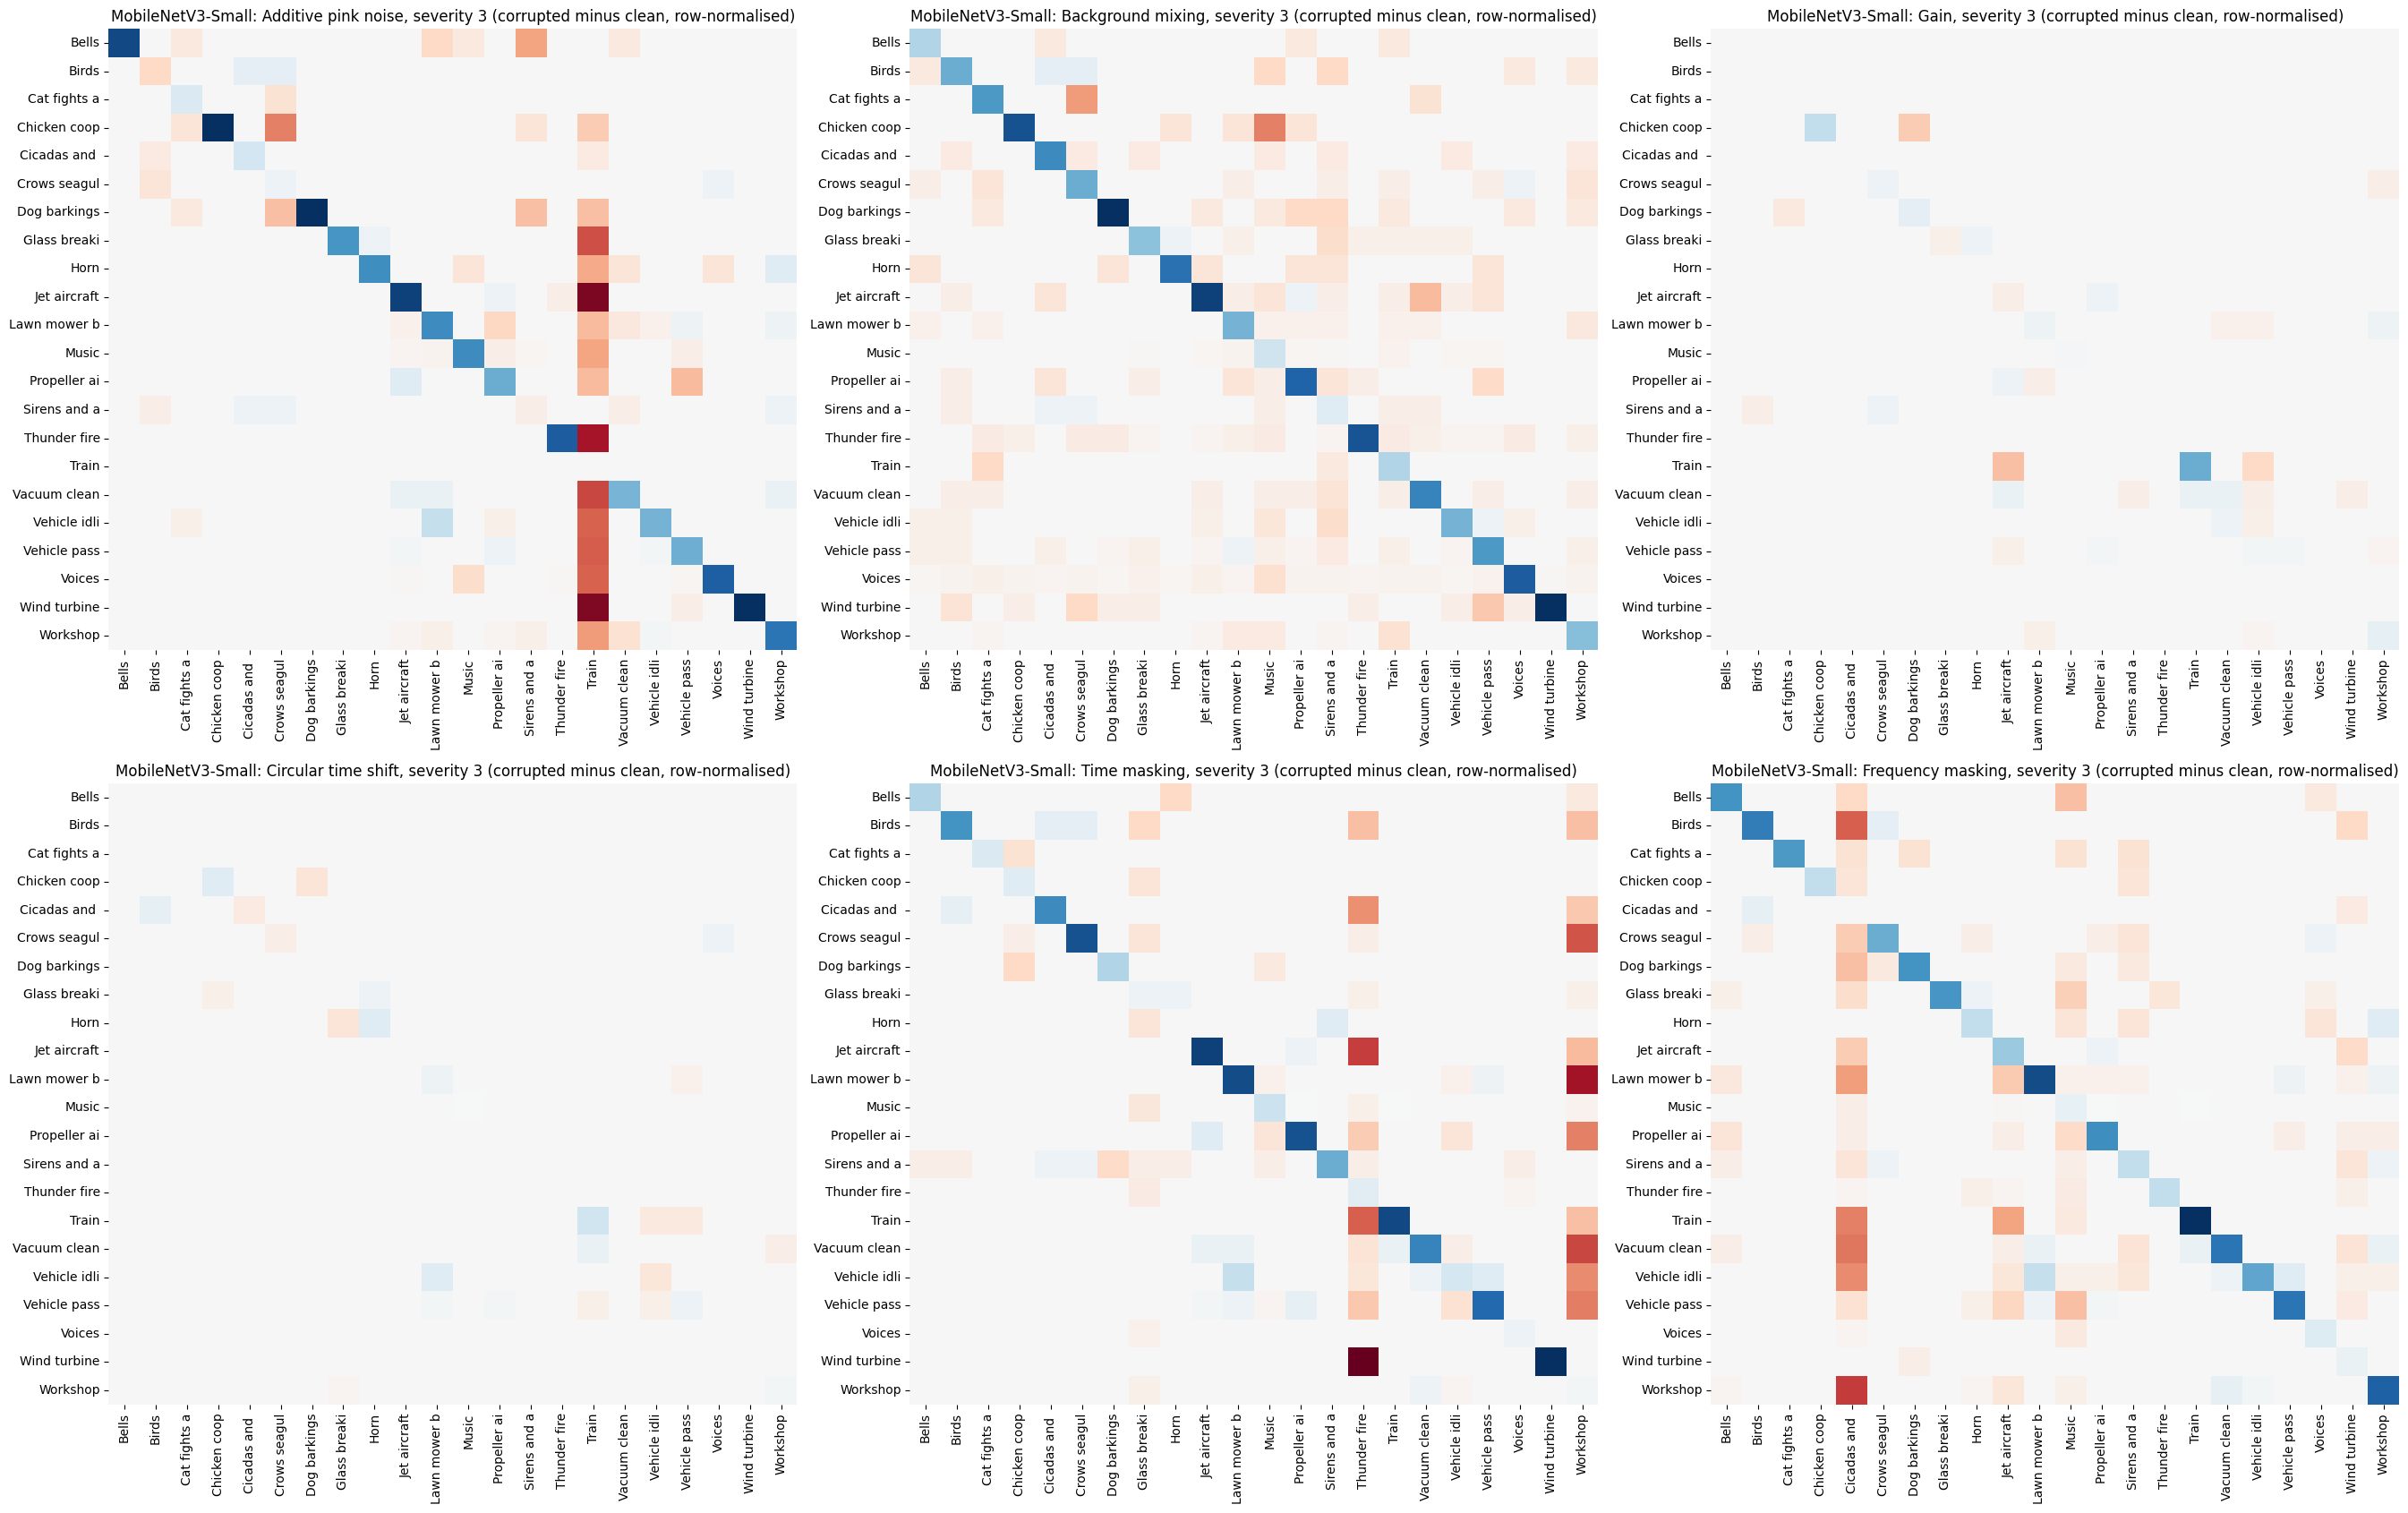

In [12]:
# Confusion-matrix transitions: clean vs corrupted (severity 3)
def norm_cm(pred):
    cm = confusion_matrix(Y, pred, labels=list(range(K))); return cm, cm / cm.sum(1, keepdims=True)

BEST = max(NETS, key=lambda m: mf1(Y, P[m][("clean", 0)].argmax(1)))
trans = []
for m in NETS:
    cm0, n0 = norm_cm(P[m][("clean", 0)].argmax(1))
    for p in PERTURBATIONS:
        cm1, n1 = norm_cm(P[m][(p, 3)].argmax(1))
        d = cm1 - cm0; np.fill_diagonal(d, 0)
        for flat in np.argsort(-d, axis=None)[:5]:
            i, j = divmod(flat, K)
            trans.append(dict(model=m, perturbation=p, true_class=CLASSES[i], predicted_as=CLASSES[j],
                              count_clean=int(cm0[i, j]), count_corrupted=int(cm1[i, j]), n_true=int(cm0[i].sum()),
                              share_increase=round(float(d[i, j]), 3)))
trans = pd.DataFrame(trans); trans.to_csv(OUT_DIR / "confusion_transitions.csv", index=False)
print(trans[trans.model == BEST].to_string(index=False))

cm0, n0 = norm_cm(P[BEST][("clean", 0)].argmax(1))
fig, axes = plt.subplots(2, 3, figsize=(27, 17))
for ax, p in zip(axes.flat, PERTURBATIONS):
    _, n1 = norm_cm(P[BEST][(p, 3)].argmax(1))
    sns.heatmap(n1 - n0, ax=ax, cmap="RdBu_r", center=0, vmin=-1, vmax=1, cbar=False,
                xticklabels=[c[:12] for c in CLASSES], yticklabels=[c[:12] for c in CLASSES])
    ax.set_title(f"{BEST}: {PERTURBATIONS[p]['label']}, severity 3 (corrupted minus clean, row-normalised)")
plt.tight_layout(); plt.savefig(OUT_DIR / "confusion_transitions_best_model.png", dpi=110); plt.show()

In [13]:
# Correct -> incorrect flips
flip_rows, flip_detail = [], []
for m in NETS:
    pc = P[m][("clean", 0)]; ok0 = pc.argmax(1) == Y
    for p in PERTURBATIONS:
        for s in (1, 2, 3):
            pp = P[m][(p, s)]; flipped = ok0 & (pp.argmax(1) != Y)
            flip_rows.append(dict(model=m, perturbation=p, severity=s, level=level_str(p, s),
                                  correct_on_clean=int(ok0.sum()), flipped=int(flipped.sum()), flip_rate=round(flipped.sum() / ok0.sum(), 4)))
            if s == 3:
                for i in np.where(flipped)[0]:
                    flip_detail.append(dict(model=m, perturbation=p, severity=3, sample_id=test_df.sample_id[i], idx=int(i),
                                            true_class=CLASSES[Y[i]], clean_pred=CLASSES[pc[i].argmax()],
                                            corrupted_pred=CLASSES[pp[i].argmax()], p_true_clean=round(float(pc[i, Y[i]]), 3),
                                            p_true_corrupted=round(float(pp[i, Y[i]]), 3), duration=round(float(test_df.duration[i]), 2)))
flip_rates = pd.DataFrame(flip_rows); flip_rates.to_csv(OUT_DIR / "flip_rates.csv", index=False)
flips = pd.DataFrame(flip_detail); flips.to_csv(OUT_DIR / "flip_examples_sev3.csv", index=False)
print(flip_rates.pivot_table(index=["perturbation", "severity"], columns="model", values="flip_rate", sort=False).to_string())

model                  Small CNN  MobileNetV3-Small    CRNN
perturbation severity                                      
noise_pink   1            0.4793             0.0723  0.1535
             2            0.7320             0.2045  0.4003
             3            0.9571             0.7177  0.8321
noise_mix    1            0.2971             0.1474  0.1578
             2            0.4671             0.3630  0.3716
             3            0.6570             0.6495  0.5997
gain         1            0.0322             0.0070  0.0129
             2            0.0230             0.0097  0.0158
             3            0.0551             0.0292  0.0301
shift        1            0.0107             0.0111  0.0201
             2            0.0092             0.0111  0.0201
             3            0.0077             0.0167  0.0187
time_mask    1            0.2021             0.0876  0.1205
             2            0.3752             0.2239  0.2023
             3            0.5069        

In [14]:
# Concrete examples (best model): clean vs corrupted log-Mel for the most confidently-correct clip that flips, per perturbation
from IPython.display import display, Audio
fig, axes = plt.subplots(len(PERTURBATIONS), 2, figsize=(15, 3.2 * len(PERTURBATIONS)))
shown = []
for r, p in enumerate(PERTURBATIONS):
    cand = flips[(flips.model == BEST) & (flips.perturbation == p)].sort_values("p_true_clean", ascending=False)
    if cand.empty:
        for c in range(2): axes[r, c].axis("off")
        axes[r, 0].set_title(f"{PERTURBATIONS[p]['label']}: no flips for {BEST}"); continue
    e = cand.iloc[0]; i = int(e.idx)
    wc = TEST_WAV[i:i + 1]; wp = perturb(TEST_WAV[i], p, 3, i, VALID[i]).unsqueeze(0)
    for c, (w, ttl) in enumerate([(wc, f"clean: predicted {e.clean_pred}"), (wp, f"{p} sev 3 ({level_str(p, 3)}): predicted {e.corrupted_pred}")]):
        img = frontend.raw_db(w)[0, 0].cpu().numpy()
        axes[r, c].imshow(img, origin="lower", aspect="auto", cmap="magma"); axes[r, c].set_title(f"{e.true_class} | {ttl}", fontsize=9)
    shown.append((e, wc, wp))
plt.tight_layout(); plt.savefig(OUT_DIR / "flip_examples.png", dpi=130); plt.show()
for e, wc, wp in shown[:3]:
    print(f"{e.perturbation}: {e.sample_id}  ({e.true_class} -> {e.corrupted_pred})")
    display(Audio(wc[0, 0].cpu().numpy(), rate=SR)); display(Audio(wp[0, 0].cpu().numpy(), rate=SR))

# Save playable examples as files (the 3 most confidently-correct clips that flip, per perturbation, best model)
audio_dir = OUT_DIR / "flip_audio"; audio_dir.mkdir(exist_ok=True); idx_rows = []
for p in PERTURBATIONS:
    cand = flips[(flips.model == BEST) & (flips.perturbation == p)].sort_values("p_true_clean", ascending=False).head(3)
    for e in cand.itertuples():
        i = int(e.idx); wp_ = perturb(TEST_WAV[i], p, 3, i, VALID[i]).cpu().numpy()[0]
        name_ = f"{p}_sev3_{Path(e.sample_id).stem}".replace(" ", "_")
        sf.write(audio_dir / f"{name_}_clean.wav", TEST_WAV[i, 0].cpu().numpy(), SR)
        sf.write(audio_dir / f"{name_}_corrupted.wav", wp_ / max(1.0, float(np.abs(wp_).max())), SR)   # peak-normalised only if it would clip
        idx_rows.append(dict(perturbation=p, severity=3, sample_id=e.sample_id, true_class=e.true_class,
                             clean_pred=e.clean_pred, corrupted_pred=e.corrupted_pred, file=name_))
pd.DataFrame(idx_rows).to_csv(OUT_DIR / "flip_audio_index.csv", index=False)
print("Saved", len(idx_rows), "clean/corrupted audio pairs to", audio_dir)


Output hidden; open in https://colab.research.google.com to view.

## Linking failures to acoustic properties
For each class, three simple descriptors are computed on the clean test clips (real audio only): **spectral flatness** (high = noise-like, broadband; low = tonal/harmonic), **spectral centroid** (where the energy sits), and **crest factor** (peak / RMS; high = impulsive). They are correlated (Spearman) with the per-class F1 drop at severity 3. With 22 classes and small test counts, treat these correlations as hints, not proof.

In [15]:
desc = []
for i in range(N):
    y = TEST_WAV[i, 0, :VALID[i]].cpu().numpy()
    S = np.abs(librosa.stft(y, n_fft=NFFT, hop_length=HOP)) if len(y) >= NFFT else np.abs(librosa.stft(np.pad(y, (0, NFFT - len(y))), n_fft=NFFT, hop_length=HOP))
    desc.append(dict(cls=CLASSES[Y[i]], flatness=float(librosa.feature.spectral_flatness(S=S).mean()),
                     centroid=float(librosa.feature.spectral_centroid(S=S, sr=SR).mean()),
                     crest=float(np.abs(y).max() / (np.sqrt((y ** 2).mean()) + 1e-9))))
acoustics = pd.DataFrame(desc).groupby("cls").mean().reindex(CLASSES).round(4)
acoustics.to_csv(OUT_DIR / "class_acoustics.csv")

drop = pcd[pcd.severity == 3].groupby(["perturbation", "cls"]).delta.mean().unstack(0).reindex(CLASSES)   # mean over the 3 models
res = []
for p in PERTURBATIONS:
    for d in acoustics.columns:
        rho, pv = spearmanr(acoustics[d], drop[p]); res.append(dict(perturbation=p, descriptor=d, spearman_rho=round(rho, 2), p_value=round(pv, 3)))
corr = pd.DataFrame(res); corr.to_csv(OUT_DIR / "acoustic_correlations.csv", index=False)
print(corr.pivot(index="perturbation", columns="descriptor", values="spearman_rho").to_string())
print("\nMost / least noise-like classes (flatness):", acoustics.flatness.sort_values().index[[0, 1, -2, -1]].tolist())

descriptor    centroid  crest  flatness
perturbation                           
freq_mask         0.62   0.17      0.59
gain              0.00   0.02     -0.00
noise_mix        -0.49   0.15     -0.45
noise_pink       -0.51   0.18     -0.41
shift             0.02   0.12     -0.05
time_mask        -0.17  -0.41     -0.00

Most / least noise-like classes (flatness): ['Wind turbine', 'Propeller aircrafts', 'Workshop', 'Glass breaking']


In [16]:
# Configuration + versions (reproducibility), then a printed summary to write the report from
FCFG = dict(seed=SEED, dataset_doi=MCFG.get("dataset_doi"), perturbations=PERTURBATIONS, test_clips=int(N),
            noise_pink="synthetic pink (1/f) noise, SNR measured over real audio only, added over the whole 4 s window",
            noise_mix="train-split clip of a different class as background (power scaled over the 4 s window), pool of %d clips" % len(pool_meta),
            bootstrap_resamples=BOOTSTRAP,
            frequency_mask="STFT n_fft 2048 hop 512, 2 random bands zeroed, inverse STFT", time_mask="4 random intervals zeroed",
            midterm_config=MCFG, env=dict(python=platform.python_version(), torch=torch.__version__, torchaudio=torchaudio.__version__,
            librosa=librosa.__version__, sklearn=sklearn.__version__, scipy=scipy.__version__, numpy=np.__version__, pandas=pd.__version__))
json.dump(FCFG, open(OUT_DIR / "final_config.json", "w"), indent=2, ensure_ascii=False, default=str)

print("=== Summary ===")
for p in PERTURBATIONS:
    sub = rob[(rob.perturbation == p) & (rob.severity == 3)].set_index("model")
    print(f"{PERTURBATIONS[p]['label']:22s} sev 3 ({level_str(p, 3):>16s}): " + " | ".join(f"{m} F1 {sub.loc[m, 'macro_f1_corrupted']:.3f} (drop {sub.loc[m, 'delta_f1']:.3f})" for m in NETS))
most = rob[rob.perturbation != "clean"].groupby("perturbation").delta_f1.mean().sort_values(ascending=False)
print("\nMean drop per perturbation (all models, all severities):"); print(most.round(3).to_string())
print("\nMost robust model overall (smallest mean drop):", rob[rob.perturbation != "clean"].groupby("model").delta_f1.mean().idxmin())
print("All outputs saved in:", OUT_DIR)

=== Summary ===
Additive pink noise    sev 3 (        0 dB SNR): Small CNN F1 0.059 (drop 0.654) | MobileNetV3-Small F1 0.324 (drop 0.574) | CRNN F1 0.204 (drop 0.632)
Background mixing      sev 3 (        0 dB SNR): Small CNN F1 0.187 (drop 0.527) | MobileNetV3-Small F1 0.212 (drop 0.686) | CRNN F1 0.246 (drop 0.590)
Gain                   sev 3 (          -12 dB): Small CNN F1 0.658 (drop 0.056) | MobileNetV3-Small F1 0.852 (drop 0.045) | CRNN F1 0.822 (drop 0.015)
Circular time shift    sev 3 (           2.0 s): Small CNN F1 0.705 (drop 0.009) | MobileNetV3-Small F1 0.882 (drop 0.015) | CRNN F1 0.822 (drop 0.015)
Time masking           sev 3 (0.5 fraction of window): Small CNN F1 0.088 (drop 0.626) | MobileNetV3-Small F1 0.403 (drop 0.495) | CRNN F1 0.328 (drop 0.508)
Frequency masking      sev 3 (0.5 fraction of 0-11 kHz): Small CNN F1 0.287 (drop 0.427) | MobileNetV3-Small F1 0.393 (drop 0.505) | CRNN F1 0.239 (drop 0.597)

Mean drop per perturbation (all models, all severities):
